# Week 3 — Visualization & Interpretation
**Project:** Food Delivery Data Analysis (`Food-Delivery-Data-Analysis-X-Kagnus`)  
**Dataset:** `data/processed/cleaned_food_delivery.csv`  
**Objective:** Convert Week 2 exploratory findings into five clear, accurately labeled visualizations with cautious, data-backed interpretations and documented limitations.


## 1. Environment Setup, Data Loading & Distance Preparation
**What & Why:** We load the cleaned dataset from Week 1, standardize column names to `snake_case`, configure consistent chart styling, and compute straight-line Haversine distance (`distance_km`) for rows with valid non-null coordinates. A shared helper `save_chart()` ensures every figure is exported consistently at 150 DPI to `visualizations/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent, high-contrast styling without visual clutter
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

DATA_PATH = "../data/processed/cleaned_food_delivery.csv"
VIZ_DIR = "../visualizations"
os.makedirs(VIZ_DIR, exist_ok=True)

def save_chart(fig, filename: str) -> None:
    """Export figure to visualizations/ at 150 DPI."""
    out_path = os.path.join(VIZ_DIR, filename)
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Exported: {out_path}")

# Load cleaned dataset and standardize column names
df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Compute Haversine straight-line distance (km) only for valid coordinates
coord_cols = [
    "restaurant_latitude", "restaurant_longitude",
    "delivery_location_latitude", "delivery_location_longitude"
]
valid_coords = df[coord_cols].notna().all(axis=1)
lat1, lon1 = np.radians(df["restaurant_latitude"]), np.radians(df["restaurant_longitude"])
lat2, lon2 = np.radians(df["delivery_location_latitude"]), np.radians(df["delivery_location_longitude"])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
df["distance_km"] = np.where(valid_coords, 6371.0 * 2.0 * np.arcsin(np.sqrt(a)), np.nan)

TARGET = "time_taken_min"
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns | Valid distance rows: {df['distance_km'].notna().sum():,}")


Loaded 45,584 rows x 21 columns | Valid distance rows: 41,944


## 2. Chart 1: Delivery Duration Distribution (Histogram)
**What & Why:** We visualize the overall distribution of `time_taken_min` across all 45,584 deliveries using 2-minute bins from 10 to 56 minutes. Adding mean and median reference lines highlights central tendency, concentration, and any right-tail skewness.


Count: 45,584 | Mean: 26.29 min | Median: 26.00 min | Min-Max: 10-54 min
15-35 min share: 74.3% | >=45 min orders: 1,803 (3.96%)


Exported: ../visualizations/01_delivery_duration_distribution.png


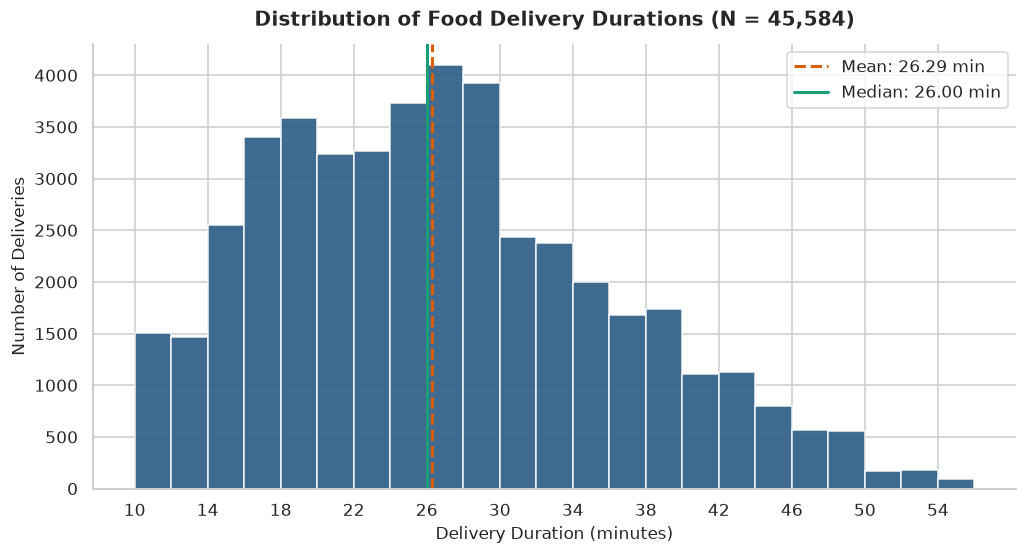

In [2]:
t = df[TARGET]
mean_val, median_val = t.mean(), t.median()
pct_15_35 = ((t >= 15) & (t <= 35)).mean() * 100
tail_45 = (t >= 45).sum()

print(f"Count: {t.count():,} | Mean: {mean_val:.2f} min | Median: {median_val:.2f} min | Min-Max: {t.min()}-{t.max()} min")
print(f"15-35 min share: {pct_15_35:.1f}% | >=45 min orders: {tail_45:,} ({tail_45 / len(t) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
bins = np.arange(10, 58, 2)  # 2-minute readable intervals covering 10-54 min
ax.hist(t, bins=bins, color="#2B5B84", edgecolor="white", alpha=0.9)

# Reference lines for central tendency
ax.axvline(mean_val, color="#D95F02", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.2f} min")
ax.axvline(median_val, color="#1B9E77", linestyle="-", linewidth=2, label=f"Median: {median_val:.2f} min")

ax.set_title("Distribution of Food Delivery Durations (N = 45,584)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Delivery Duration (minutes)", fontsize=11)
ax.set_ylabel("Number of Deliveries", fontsize=11)
ax.set_xticks(np.arange(10, 56, 4))
ax.legend(frameon=True)
plt.tight_layout()

save_chart(fig, "01_delivery_duration_distribution.png")
plt.show()


### Interpretation — Chart 1
The histogram shows delivery durations across all 45,584 orders spanning 10 to 54 minutes, with 74.3% of deliveries concentrated between 15 and 35 minutes (mean = 26.29 min, median = 26.00 min) and a mild right tail extending toward 45–54 minutes (1,803 orders, or 3.96%). This unimodal pattern indicates that most deliveries complete within a consistent ~20–30 minute window, while a smaller subset of prolonged trips pulls the mean slightly above the median. As a limitation, pooling all cities, traffic states, and weather conditions into one histogram masks underlying multi-modal sub-groups such as festival-day or jam-hour deliveries.


## 3. Chart 2: Traffic Comparison (Bar Chart of Median Duration)
**What & Why:** To compare delivery performance across congestion levels without distortion from extreme values, we plot **median** delivery duration for each `road_traffic_density` category (`Low`, `Medium`, `High`, `Jam`), ordered by severity and annotated with both median values and group sample sizes (`n`).


,count,median,mean
road_traffic_density,,,
Low,15476,20.0,21.266671
Medium,10945,27.0,26.699680
High,4423,27.0,27.240109
Jam,14139,31.0,31.176038


Exported: ../visualizations/02_traffic_comparison.png


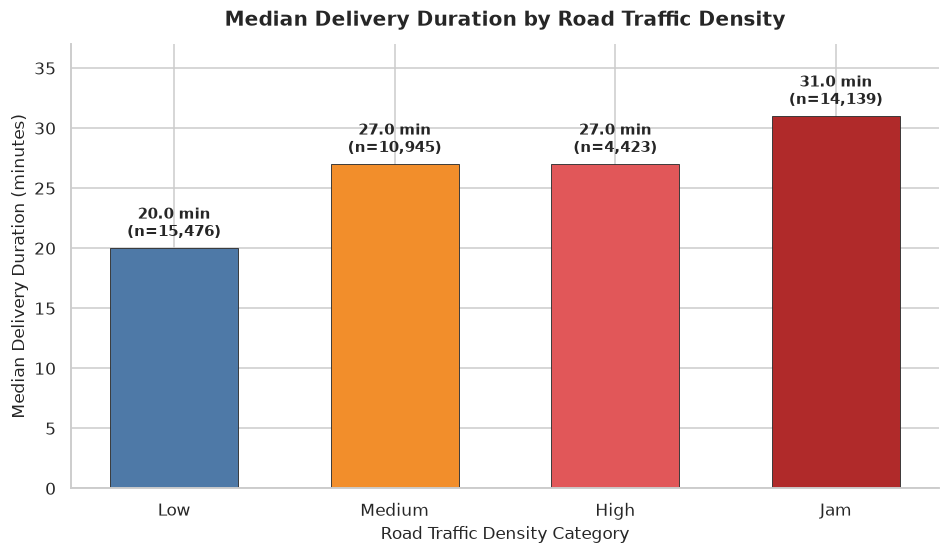

In [3]:
traffic_order = ["Low", "Medium", "High", "Jam"]
traffic_stats = (
    df.dropna(subset=["road_traffic_density"])
    .groupby("road_traffic_density")[TARGET]
    .agg(count="count", median="median", mean="mean")
    .reindex(traffic_order)
)
display(traffic_stats)

fig, ax = plt.subplots(figsize=(8.8, 5.2))
colors = ["#4E79A7", "#F28E2B", "#E15759", "#B02A2A"]
bars = ax.bar(traffic_stats.index, traffic_stats["median"], color=colors, width=0.58, edgecolor="#333333", linewidth=0.6)

# Annotate median duration and sample size directly on bars
for bar, (_, row) in zip(bars, traffic_stats.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{row['median']:.1f} min\n(n={int(row['count']):,})",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

ax.set_title("Median Delivery Duration by Road Traffic Density", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Road Traffic Density Category", fontsize=11)
ax.set_ylabel("Median Delivery Duration (minutes)", fontsize=11)
ax.set_ylim(0, traffic_stats["median"].max() + 6)
plt.tight_layout()

save_chart(fig, "02_traffic_comparison.png")
plt.show()


### Interpretation — Chart 2
The bar chart shows that median delivery duration increases from 20.0 minutes in `Low` traffic (`n=15,476`) to 27.0 minutes in both `Medium` (`n=10,945`) and `High` (`n=4,423`) traffic, reaching 31.0 minutes in `Jam` conditions (`n=14,139`). This 11.0-minute median gap between `Low` and `Jam` conditions suggests that heavier road congestion is strongly associated with slower deliveries, though observational comparisons alone do not prove traffic directly causes the entire delay. One limitation is that 601 orders with missing traffic labels are excluded, and bar heights do not display within-category spread or overlapping factors such as weather and order batching.


## 4. Chart 3: Weather Comparison (Bar Chart of Average Duration)
**What & Why:** We compute and plot the **average (mean)** delivery duration across all six `weather_conditions` categories, sorted from highest to lowest mean duration, to identify which atmospheric conditions coincide with slower or faster deliveries.


,count,mean,median
weather_conditions,,,
Cloudy,7533,28.917164,28.0
Fog,7653,28.914674,28.0
Windy,7422,26.118836,26.0
Sandstorms,7494,25.875500,26.0
Stormy,7584,25.868803,26.0
Sunny,7282,21.856770,20.0


Exported: ../visualizations/03_weather_comparison.png


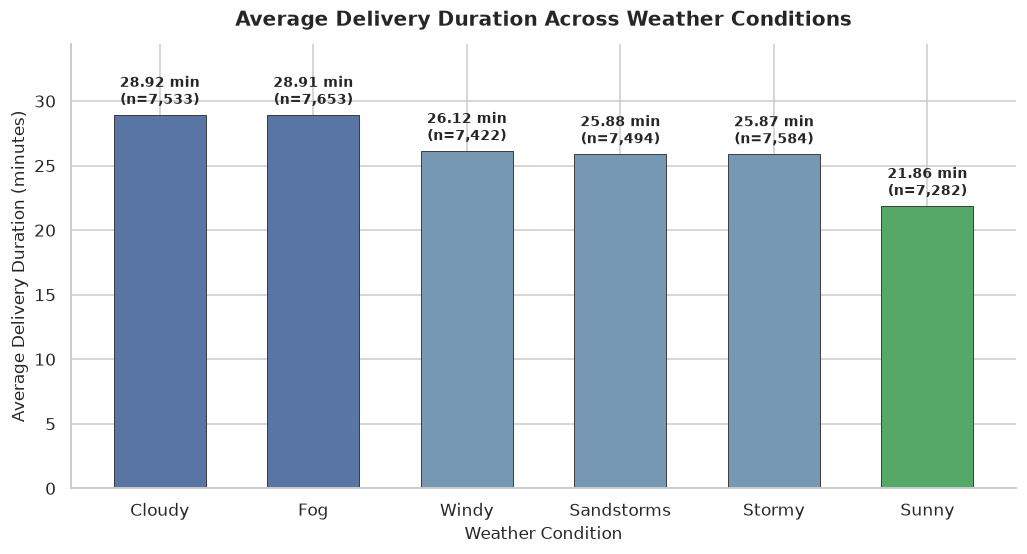

In [4]:
weather_stats = (
    df.dropna(subset=["weather_conditions"])
    .groupby("weather_conditions")[TARGET]
    .agg(count="count", mean="mean", median="median")
    .sort_values("mean", ascending=False)
)
display(weather_stats)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
palette = ["#5975A4" if m > 27 else "#7698B3" if m > 24 else "#55A868" for m in weather_stats["mean"]]
bars = ax.bar(weather_stats.index, weather_stats["mean"], color=palette, width=0.6, edgecolor="#333333", linewidth=0.6)

# Annotate exact calculated mean and sample count
for bar, (_, row) in zip(bars, weather_stats.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['mean']:.2f} min\n(n={int(row['count']):,})",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

ax.set_title("Average Delivery Duration Across Weather Conditions", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Weather Condition", fontsize=11)
ax.set_ylabel("Average Delivery Duration (minutes)", fontsize=11)
ax.set_ylim(0, weather_stats["mean"].max() + 5.5)
plt.tight_layout()

save_chart(fig, "03_weather_comparison.png")
plt.show()


### Interpretation — Chart 3
Average delivery duration is highest during `Cloudy` (28.92 min, `n=7,533`) and `Fog` (28.91 min, `n=7,653`) conditions, moderate during `Windy` (26.12 min), `Sandstorms` (25.88 min), and `Stormy` (25.87 min), and lowest during `Sunny` weather (21.86 min, `n=7,282`). These differences indicate that low-visibility or overcast conditions are associated with roughly 7 minutes longer average delivery times compared to clear `Sunny` weather, possibly due to cautious riding speeds or coinciding peak-hour demand. A key limitation is that 616 orders lack weather records and arithmetic means can be pulled upward by extreme delays, while categorical weather labels do not capture severity or precipitation intensity.


## 5. Chart 4: Distance vs Delivery Duration (Scatter Plot)
**What & Why:** We plot straight-line Haversine distance (`distance_km`) against `time_taken_min` for the 41,944 orders with valid coordinates, overlaid with a fitted linear trend line. Using low point opacity (`alpha=0.12`) prevents overplotting and reveals density bands and unusual short-distance/long-duration or long-distance/short-duration points.


Valid rows: 41,944 | Excluded (missing GPS): 3,640
Pearson r = 0.320 (r^2 = 0.103) | Spearman rho = 0.319
Unusual points -> <5 km & >=45 min: 123 | >15 km & <=20 min: 1,605


Exported: ../visualizations/04_distance_vs_duration.png


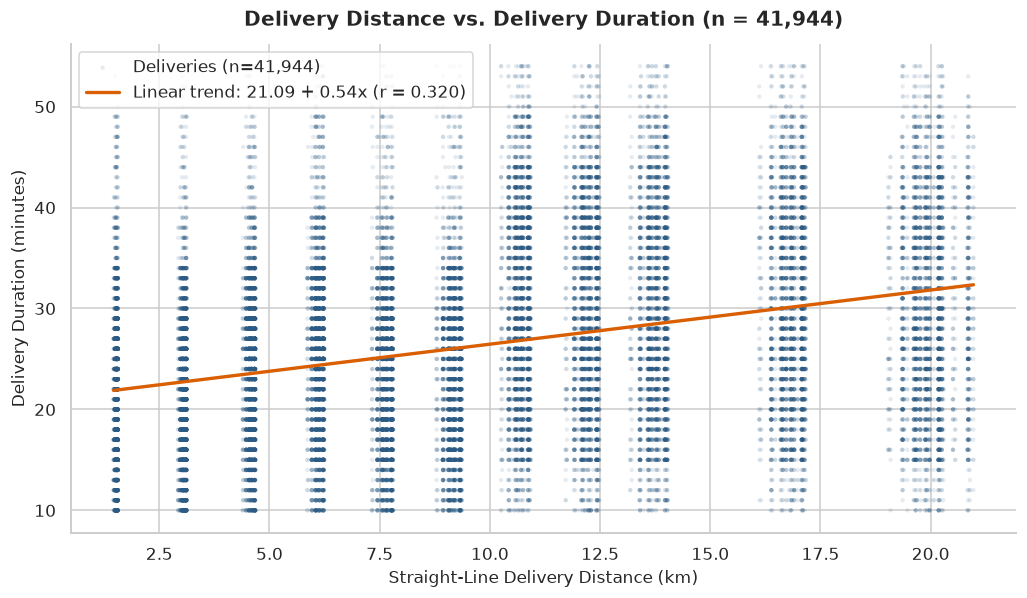

In [5]:
d = df.dropna(subset=["distance_km", TARGET])
pearson_r = d["distance_km"].corr(d[TARGET])
spearman_rho = d["distance_km"].rank().corr(d[TARGET].rank())
slope, intercept = np.polyfit(d["distance_km"], d[TARGET], 1)

short_slow = ((d["distance_km"] < 5) & (d[TARGET] >= 45)).sum()
long_fast = ((d["distance_km"] > 15) & (d[TARGET] <= 20)).sum()
print(f"Valid rows: {len(d):,} | Excluded (missing GPS): {len(df) - len(d):,}")
print(f"Pearson r = {pearson_r:.3f} (r^2 = {pearson_r**2:.3f}) | Spearman rho = {spearman_rho:.3f}")
print(f"Unusual points -> <5 km & >=45 min: {short_slow:,} | >15 km & <=20 min: {long_fast:,}")

fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.scatter(d["distance_km"], d[TARGET], s=8, alpha=0.12, color="#2B5B84", edgecolors="none", label="Deliveries (n=41,944)")

xs = np.linspace(d["distance_km"].min(), d["distance_km"].max(), 100)
ax.plot(xs, intercept + slope * xs, color="#D95F02", linewidth=2.2,
        label=f"Linear trend: {intercept:.2f} + {slope:.2f}x (r = {pearson_r:.3f})")

ax.set_title("Delivery Distance vs. Delivery Duration (n = 41,944)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Straight-Line Delivery Distance (km)", fontsize=11)
ax.set_ylabel("Delivery Duration (minutes)", fontsize=11)
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()

save_chart(fig, "04_distance_vs_duration.png")
plt.show()


### Interpretation — Chart 4
The scatter plot reveals a weak-to-moderate positive relationship between straight-line distance and delivery duration (Pearson `r = 0.320`, `r² = 0.103`, Spearman `ρ = 0.319` across 41,944 valid orders), along with notable edge cases such as short trips under 5 km taking 45–54 minutes (`n=307` in the upper-left) and long trips over 15 km completing in 20 minutes or less (`n=930` in the lower-right). This indicates that while longer distances tend to increase delivery time, straight-line distance explains only ~10.3% of duration variance, meaning operational factors like traffic, preparation time, and batching play a larger role. Limitations include the exclusion of 3,640 orders with missing `(0, 0)` coordinates and the use of straight-line Haversine distance rather than actual road-network mileage.


## 6. Chart 5: Vehicle Comparison (Box Plot)
**What & Why:** A box plot compares the full delivery-duration distribution across `type_of_vehicle` categories (`electric_scooter`, `scooter`, `bicycle`, `motorcycle`), clearly displaying the median line, interquartile range (IQR box), 1.5×IQR whiskers, and any plotted statistical outliers.


,count,median,q1,q3,mean,iqr
type_of_vehicle,,,,,,
electric_scooter,3814,24.0,17.0,30.00,24.470110,13.00
scooter,15273,24.0,17.0,30.00,24.478819,13.00
bicycle,68,26.0,19.0,32.25,26.426471,13.25
motorcycle,26429,26.0,20.0,34.00,27.605774,14.00


/tmp/ipykernel_36891/2062482728.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_36891/2062482728.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{v.replace('_', ' ').title()}\n(n={int(veh_stats.loc[v, 'count']):,})" for v in vehicle_order])


Exported: ../visualizations/05_vehicle_comparison.png


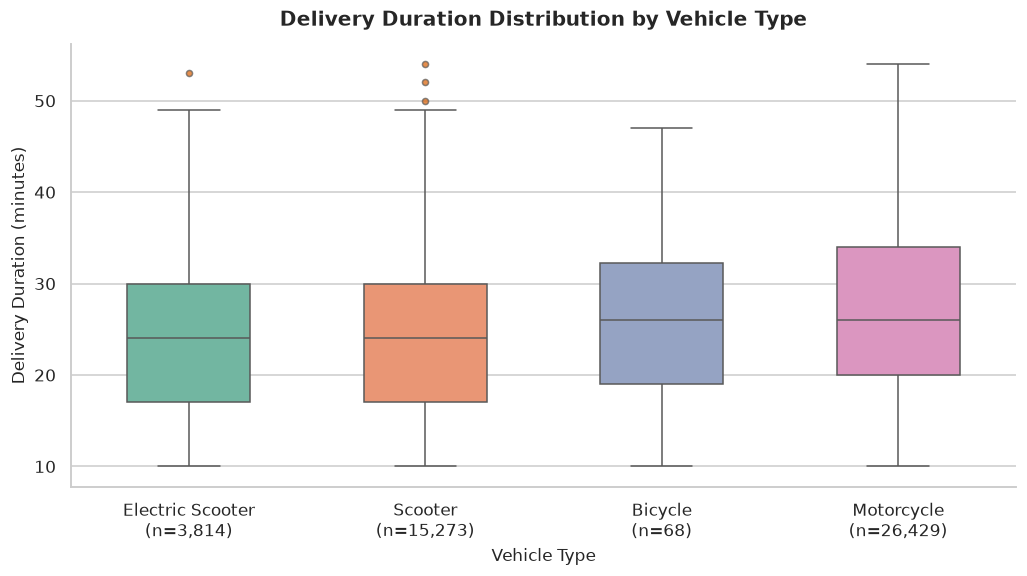

In [6]:
vehicle_order = ["electric_scooter", "scooter", "bicycle", "motorcycle"]
veh_stats = df.groupby("type_of_vehicle")[TARGET].agg(
    count="count",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    mean="mean"
).reindex(vehicle_order)
veh_stats["iqr"] = veh_stats["q3"] - veh_stats["q1"]
display(veh_stats)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
sns.boxplot(
    data=df,
    x="type_of_vehicle",
    y=TARGET,
    order=vehicle_order,
    palette="Set2",
    width=0.52,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "#D95F02", "alpha": 0.7},
    ax=ax
)

# Readable x-tick labels including group counts
ax.set_xticklabels([f"{v.replace('_', ' ').title()}\n(n={int(veh_stats.loc[v, 'count']):,})" for v in vehicle_order])
ax.set_title("Delivery Duration Distribution by Vehicle Type", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Vehicle Type", fontsize=11)
ax.set_ylabel("Delivery Duration (minutes)", fontsize=11)
plt.tight_layout()

save_chart(fig, "05_vehicle_comparison.png")
plt.show()


### Interpretation — Chart 5
The box plot shows that `electric_scooter` (`n=3,814`) and `scooter` (`n=15,273`) deliveries share a lower median duration of 24.0 minutes (IQR = 13.0 min, Q1–Q3: 17–30 min) with 1 and 3 upper outliers above 49.5 minutes, whereas `motorcycle` (`n=26,429`) has a higher median of 26.0 minutes and wider IQR of 14.0 minutes (Q1–Q3: 20–34 min), and `bicycle` (`n=68`) shows a 26.0-minute median (IQR = 13.25 min) with no statistical outliers. This suggests that scooters and electric scooters tend to achieve slightly faster central delivery times than motorcycles, though substantial overlap across all boxes shows that vehicle type alone does not dictate delivery speed. A key limitation is severe class imbalance (`bicycle` has only 68 observations vs. 26,429 for `motorcycle`), and the plot does not adjust for confounding factors such as traffic density or multi-order batching.


## 7. Week 3 Export Verification
**What & Why:** Confirm that all five required PNG charts exist in `visualizations/` and are non-empty.


In [7]:
expected_files = [
    "01_delivery_duration_distribution.png",
    "02_traffic_comparison.png",
    "03_weather_comparison.png",
    "04_distance_vs_duration.png",
    "05_vehicle_comparison.png",
]
for fname in expected_files:
    fpath = os.path.join(VIZ_DIR, fname)
    assert os.path.exists(fpath) and os.path.getsize(fpath) > 0, f"Missing or empty: {fpath}"
    print(f"Verified {fname} ({os.path.getsize(fpath) / 1024:.1f} KB)")


Verified 01_delivery_duration_distribution.png (61.8 KB)
Verified 02_traffic_comparison.png (61.3 KB)
Verified 03_weather_comparison.png (73.2 KB)
Verified 04_distance_vs_duration.png (343.7 KB)
Verified 05_vehicle_comparison.png (52.6 KB)
